# Mandatory assignment 3

**GitHub repository:** https://github.com/bjornjohanbakke-nhh/TECH2-H26-assignment3

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('SCF_10pct.csv')

df.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 5808 entries, 0 to 5807
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      5808 non-null   int64  
 1   year    5808 non-null   int64  
 2   age     5808 non-null   int64  
 3   educ    5792 non-null   float64
 4   stocks  5790 non-null   float64
 5   equity  5792 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 272.4 KB


In [2]:
df.isna().sum()

id         0
year       0
age        0
educ      16
stocks    18
equity    16
dtype: int64

In [3]:
for col in ['id', 'year', 'age', 'educ', 'stocks', 'equity']:
    n_before = len(df)
    df = df.dropna(subset=col)
    n_after = len(df)
    print(f'{col}: dropped {n_before - n_after}, remaining {n_after}')

id: dropped 0, remaining 5808
year: dropped 0, remaining 5808
age: dropped 0, remaining 5808
educ: dropped 16, remaining 5792
stocks: dropped 18, remaining 5774
equity: dropped 16, remaining 5758


In [4]:
n_before = len(df)
df = df[(df['age'] >= 25) & (df['age'] <= 89)]
n_after = len(df)
print(f'age 25-89: dropped {n_before - n_after}, remaining {n_after}')

age 25-89: dropped 326, remaining 5432


In [5]:
df['direct'] = (df['stocks'] > 0).astype(int)
df['overall'] = (df['equity'] > 0).astype(int)

df.head(15)

,id,year,age,educ,stocks,equity,direct,overall
0,0,1989,35,2.0,0.0,0.0,0,0
1,1,1989,33,2.0,0.0,0.0,0,0
2,2,1989,62,1.0,0.0,0.0,0,0
4,4,1989,70,1.0,0.0,0.0,0,0
5,5,1989,50,1.0,0.0,0.0,0,0
6,6,1989,44,2.0,0.0,0.0,0,0
7,7,1989,55,1.0,0.0,0.0,0,0
8,8,1989,62,1.0,0.0,0.0,0,0
9,9,1989,77,1.0,6916.8,6916.8,1,1
10,10,1989,34,3.0,0.0,0.0,0,0


***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

In [6]:
def participation_rate(indicator):
    """
    Compute the participation rate as the percentage of ones.

    Parameters
    ----------
    indicator : sequence of int
        Nonempty sequence of 0/1 values.

    Returns
    -------
    float
        Share of ones in percent.
    """
    count = 0
    for value in indicator:
        count += value
    return count / len(indicator) * 100


# Test on a small example: 2 ones out of 5 values should give 40%
print(participation_rate([0, 1, 0, 0, 1]))

direct_rate = participation_rate(df['direct'])
overall_rate = participation_rate(df['overall'])

print(f'Direct participation rate: {direct_rate:.1f}%')
print(f'Overall participation rate: {overall_rate:.1f}%')

40.0
Direct participation rate: 17.0%
Overall participation rate: 49.4%


In [7]:
direct_rate_mean = df['direct'].mean() * 100
overall_rate_mean = df['overall'].mean() * 100

print(f'Direct participation rate (mean): {direct_rate_mean:.1f}%')
print(f'Overall participation rate (mean): {overall_rate_mean:.1f}%')

Direct participation rate (mean): 17.0%
Overall participation rate (mean): 49.4%


***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

In [8]:
direct_rates = []
overall_rates = []
for educ in range(1, 5):
    subset = df[df['educ'] == educ]
    direct = participation_rate(subset['direct'])
    overall = participation_rate(subset['overall'])
    direct_rates.append(direct)
    overall_rates.append(overall)
    print(f'Education {educ}: direct {direct:.1f}%, overall {overall:.1f}%')

Education 1: direct 4.4%, overall 17.3%
Education 2: direct 11.4%, overall 39.9%
Education 3: direct 13.5%, overall 48.3%
Education 4: direct 30.5%, overall 73.5%


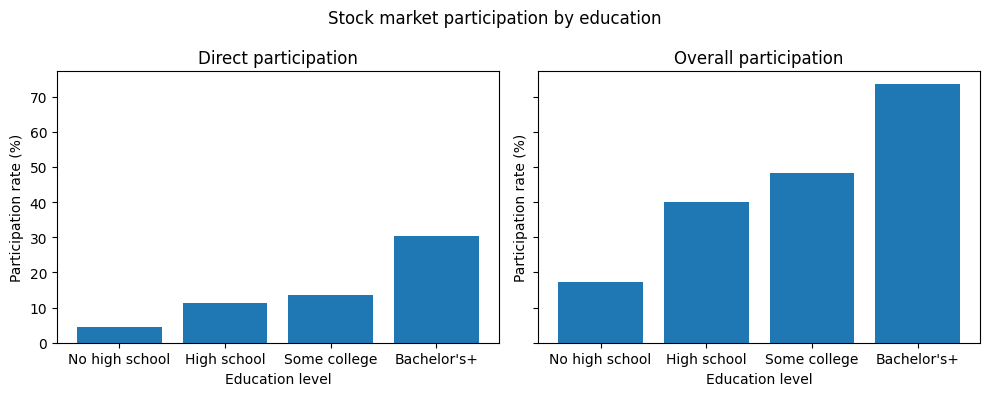

In [9]:
educ_labels = ['No high school', 'High school', 'Some college', "Bachelor's+"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

axes[0].bar([1, 2, 3, 4], direct_rates)
axes[0].set_title('Direct participation')
axes[0].set_xlabel('Education level')
axes[0].set_ylabel('Participation rate (%)')
axes[0].set_xticks([1, 2, 3, 4], educ_labels)

axes[1].bar([1, 2, 3, 4], overall_rates)
axes[1].set_title('Overall participation')
axes[1].set_xlabel('Education level')
axes[1].set_ylabel('Participation rate (%)')
axes[1].set_xticks([1, 2, 3, 4], educ_labels)

fig.suptitle('Stock market participation by education')
fig.tight_layout()
plt.show()

Both direct and overall participation increase with education. Direct participation rises from 4.4% for households without a high school degree to 30.5% for those with a bachelor's degree, while overall participation rises from 17.3% to 73.5%. The largest jump occurs between some college education and a bachelor's degree, where direct participation more than doubles.

***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

In [10]:
years = range(1989, 2023, 3)
direct_by_year = []
overall_by_year = []
for year in years:
    subset = df[df['year'] == year]
    direct = participation_rate(subset['direct'])
    overall = participation_rate(subset['overall'])
    direct_by_year.append(direct)
    overall_by_year.append(overall)
    print(f'Year {year}: direct {direct:.1f}%, overall {overall:.1f}%')

Year 1989: direct 15.6%, overall 31.6%
Year 1992: direct 18.3%, overall 40.1%
Year 1995: direct 15.7%, overall 45.9%
Year 1998: direct 19.9%, overall 51.2%
Year 2001: direct 21.8%, overall 57.0%
Year 2004: direct 18.9%, overall 54.7%
Year 2007: direct 17.3%, overall 56.5%
Year 2010: direct 17.4%, overall 50.3%
Year 2013: direct 14.8%, overall 49.9%
Year 2016: direct 12.3%, overall 52.0%
Year 2019: direct 12.4%, overall 49.8%
Year 2022: direct 19.2%, overall 54.3%


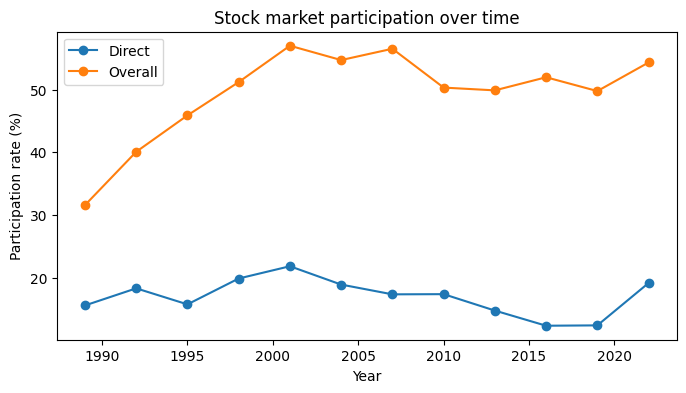

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(years, direct_by_year, marker='o', label='Direct')
plt.plot(years, overall_by_year, marker='o', label='Overall')
plt.title('Stock market participation over time')
plt.xlabel('Year')
plt.ylabel('Participation rate (%)')
plt.legend()
plt.show()

In [12]:
direct_change = direct_by_year[-1] - direct_by_year[0]
overall_change = overall_by_year[-1] - overall_by_year[0]
print(
    f'Change in direct participation 1989-2022: {direct_change:.1f} percentage points'
)
print(
    f'Change in overall participation 1989-2022: {overall_change:.1f} percentage points'
)

Change in direct participation 1989-2022: 3.6 percentage points
Change in overall participation 1989-2022: 22.8 percentage points


Overall participation rose sharply from 31.6% in 1989 to 57.0% in 2001, and has since stagnated between roughly 50% and 57%. Direct participation, by contrast, shows no clear trend: it peaked at 21.8% in 2001, fell to a low of 12.3% in 2016, and then rebounded to 19.2% in 2022. This suggests that the increase in overall participation came mainly through indirect holdings such as mutual funds and retirement accounts rather than direct stock ownership.

***
## AI-use statement

I used Claude (Anthropic), through the Claude Code extension in VS Code, as a tutor
while working on this assignment. It worked step by step: it explained concepts
(for example `dropna(subset=...)`, boolean filtering, `.astype(int)`, list indexing
and subplots), asked guiding questions, pointed out errors in my code and checked my
results against expected values. I wrote most of the code and the written answers
myself based on this feedback. When I was stuck, the AI sometimes showed me a line of
code directly (for example creating the indicator columns and updating the counter
in `participation_rate`).

At the end, I asked the AI to tidy up the notebook: removing test code and
leftovers, splitting the analysis and plotting code into separate cells, adding a
docstring, improving figure labels, fixing typos and numbers in my written answers,
and formatting the code with `ruff`. The AI also drafted this statement, which I
reviewed.